# Домашнее задание №2

В этой работе разберём файл `exp_data_seed_4762709.csv`.
Сначала проверим качество данных и распределение пользователей по группам,
затем сравним конверсию, ошибки и отдельные платформы. После этого попробуем
скорректировать оценку и решим, стоит ли запускать фичу.

Выберем уровень значимости 0,05. Для конверсии используем двусторонний Z-тест,
а для ошибок проверим именно увеличение их доли. Для трёх платформ применим
поправку Бонферрони.


In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import statsmodels
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep
from statsmodels.stats.multitest import multipletests
import matplotlib
if 'get_ipython' not in globals():
    matplotlib.use('Agg')
import matplotlib.pyplot as plt

ALPHA = 0.05
SEED = 4762709
DATA = Path('exp_data_seed_4762709.csv')
if not DATA.is_file():
    raise FileNotFoundError(
        f'Не найден {DATA.name}. Загрузите CSV в рабочую папку ноутбука: {Path.cwd()}.'
    )
df = pd.read_csv(DATA)
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:.6f}')
plt.rcParams.update({'figure.dpi': 120, 'font.family': 'DejaVu Sans'})
print(f'Seed: {SEED}; файл: {DATA.name}; строк: {len(df)}')
print('SHA256:', hashlib.sha256(DATA.read_bytes()).hexdigest())

Seed: 4762709; файл: exp_data_seed_4762709.csv; строк: 2095
SHA256: 235eb65dbc09f81acb8417bb01c16fcf4706469f6e3e136c0a9f79abede4c229


## 1. Подготовим данные

Загрузим CSV и проверим названия столбцов, пропуски, повторы пользователей и
допустимые значения. Затем посмотрим, сколько пользователей попало в каждую
группу, какая у них конверсия и как часто возникают ошибки.

Время входа переведём из долей суток в `timedelta`. Календарных дат у нас нет,
поэтому проверить, действительно ли `weekend` соответствует выходному, не получится.
Также один CSV не позволяет проверить все особенности логирования и независимость
пользователей. Если у пользователя одновременно есть ошибка и конверсия, это
не обязательно ошибка данных, целевое действие могло произойти с другой попытки.

In [2]:
required = ['user_id', 'variant', 'converted', 'error_flag', 'weekend', 'platform', 'entry_time']
checks = {
    'Схема соответствует заданию': set(df.columns) == set(required),
    'Нет пропусков': not df.isna().any().any(),
    'Нет повторов user_id': df.user_id.is_unique,
    'Нет полных дублей': not df.duplicated().any(),
    'Обе группы и только они': set(df.variant) == {'control', 'test'},
    'Бинарные признаки корректны': all(df[c].isin([0, 1]).all() for c in ['converted', 'error_flag', 'weekend']),
    'Платформы корректны': df.platform.isin([0, 1, 2]).all(),
    'Время конечно и в [0,1]': np.isfinite(df.entry_time).all() and df.entry_time.between(0, 1).all(),
    'ID целые и неотрицательные': (df.user_id >= 0).all() and (df.user_id % 1 == 0).all(),
}
print(pd.Series(checks, name='Пройдена проверка').to_string())
assert all(checks.values()), 'Нарушено качество входных данных'
df['time_delta'] = pd.to_timedelta(df.entry_time, unit='D')
summary = df.groupby('variant').agg(n=('user_id', 'size'), conversions=('converted', 'sum'),
    conversion=('converted', 'mean'), errors=('error_flag', 'sum'), error_rate=('error_flag', 'mean'),
    weekend_share=('weekend', 'mean'), entry_mean=('entry_time', 'mean')).reindex(['control', 'test'])
print('\nБазовая сводка:\n', summary)


Схема соответствует заданию    True
Нет пропусков                  True
Нет повторов user_id           True
Нет полных дублей              True
Обе группы и только они        True
Бинарные признаки корректны    True
Платформы корректны            True
Время конечно и в [0,1]        True
ID целые и неотрицательные     True

Базовая сводка:
             n  conversions  conversion    errors  error_rate  weekend_share  entry_mean
variant                                                                                
control  1141          137    0.120070 27.000000    0.023663       0.078878    0.505436
test      954          121    0.126834 68.000000    0.071279       0.553459    0.494245


## 2. Проверим размеры групп и баланс

По условию ожидаем распределение 50/50. Проверим это с помощью критерия χ².
Если p-value окажется меньше 0,05, будем считать, что обнаружен SRM — размеры
групп не соответствуют ожидаемому распределению. Сам SRM ещё не объясняет причину.

Теперь сравним `weekend` и `entry_time` с помощью t-теста Уэлча. Для бинарного
`weekend` сравнение средних означает сравнение долей. Дополнительно посчитаем SMD,
он показывает размер дисбаланса в единицах стандартного отклонения. Распределение
платформ проверим через таблицу сопряжённости. Различие ковариаты между группами
особенно важно, если эта же ковариата связана с конверсией.

In [3]:
control = df[df.variant == 'control']
test = df[df.variant == 'test']
srm = stats.chisquare(summary.n.to_numpy(), f_exp=np.repeat(len(df) / 2, 2))
print(f'SRM: chi2={srm.statistic:.6f}, df=1, p={srm.pvalue:.8g}:',
      'SRM обнаружен' if srm.pvalue < ALPHA else 'SRM нет (не обнаружен)')
balance_rows = []
for cov in ['weekend', 'entry_time']:
    t = stats.ttest_ind(test[cov], control[cov], equal_var=False)
    difference = test[cov].mean() - control[cov].mean()
    smd = difference / np.sqrt((test[cov].var() + control[cov].var()) / 2)
    balance_rows.append(dict(covariate=cov, control_mean=control[cov].mean(),
        test_mean=test[cov].mean(), difference=difference, smd=smd, p=t.pvalue))
balance = pd.DataFrame(balance_rows).set_index('covariate')
print('\nБаланс:\n', balance)
platform_balance = stats.chi2_contingency(pd.crosstab(df.variant, df.platform))
print(f'Баланс платформ: chi2={platform_balance.statistic:.4f}, p={platform_balance.pvalue:.6g}')


SRM: chi2=16.691647, df=1, p=4.3974199e-05: SRM обнаружен

Баланс:
             control_mean  test_mean  difference       smd        p
covariate                                                         
weekend         0.078878   0.553459    0.474581  1.186227 0.000000
entry_time      0.505436   0.494245   -0.011191 -0.038450 0.380933
Баланс платформ: chi2=0.5745, p=0.750321


## 3. Посмотрим на основную метрику

Рассчитаем конверсию каждой группы, абсолютную разницу и относительный lift.
Нулевая гипотеза Z-теста: конверсия test равна конверсии control. Для разницы
долей построим 95% доверительный интервал методом Newcombe, а для относительного
lift — приближённый интервал через логарифм отношения рисков.

Пока не будем делать вывод о запуске. Даже маленький p-value не исправляет
нарушенную рандомизацию. Для проверки чувствительности результата также
посмотрим на точный тест Фишера, не выбирая метод по более удобному p-value.

In [4]:
def compare_proportions(data, metric, alternative='two-sided'):
    """Сравнение test − control; обе группы должны присутствовать."""
    grouped = data.groupby('variant')[metric].agg(['sum', 'size'])
    x_t, n_t = grouped.loc['test', ['sum', 'size']]
    x_c, n_c = grouped.loc['control', ['sum', 'size']]
    p_t, p_c = x_t / n_t, x_c / n_c
    z, p = proportions_ztest([x_t, x_c], [n_t, n_c], alternative=alternative)
    lo, hi = confint_proportions_2indep(x_t, n_t, x_c, n_c, method='newcomb', compare='diff')
    fisher_alternative = {'larger': 'greater', 'smaller': 'less'}.get(alternative, alternative)
    fisher = stats.fisher_exact([[x_t, n_t-x_t], [x_c, n_c-x_c]], alternative=fisher_alternative).pvalue
    return dict(n_control=int(n_c), n_test=int(n_t), x_control=int(x_c), x_test=int(x_t),
        control_rate=p_c, test_rate=p_t, difference=p_t-p_c, lift=p_t/p_c-1 if p_c else np.nan,
        ci_low=lo, ci_high=hi, z=z, p=p, fisher_p=fisher)

primary = compare_proportions(df, 'converted')
print(pd.Series(primary).to_string())
rr_se = np.sqrt(1/primary['x_test'] - 1/primary['n_test'] + 1/primary['x_control'] - 1/primary['n_control'])
lift_ci = np.exp(np.log(1 + primary['lift']) + np.array([-1, 1])*stats.norm.ppf(.975)*rr_se)-1
print('95% ДИ относительного lift:', lift_ci)
print(f'Для сравнения: точный Fisher p={primary["fisher_p"]:.6g}.')
print('Все количества успехов и неуспехов >= 5:', min(primary['x_test'], primary['x_control'],
    primary['n_test']-primary['x_test'], primary['n_control']-primary['x_control']) >= 5)

n_control      1141.000000
n_test          954.000000
x_control       137.000000
x_test          121.000000
control_rate      0.120070
test_rate         0.126834
difference        0.006764
lift              0.056336
ci_low           -0.021365
ci_high           0.035427
z                 0.469208
p                 0.638921
fisher_p          0.640987
95% ДИ относительного lift: [-0.15977962  0.32803933]
Для сравнения: точный Fisher p=0.640987.
Все количества успехов и неуспехов >= 5: True


## 4. Проверим частоту ошибок

Конверсия может вырасти одновременно с ухудшением работы страницы. Поэтому
отдельно проверим `error_flag` — защитную метрику или guardrail.

Нулевая гипотеза: доля ошибок в test не выше control. Альтернатива: в test
ошибок больше. Используем односторонний Z-тест и дополнительно точный тест
Фишера. Доверительный интервал разницы оставим двусторонним, на уровне 95%.
По условию значимый рост ошибок блокирует запуск, даже если конверсия выросла.

In [5]:
guardrail = compare_proportions(df, 'error_flag', alternative='larger')
print(pd.Series(guardrail).to_string())
print('Guardrail:', 'НАРУШЕН — остановить тест/не запускать' if guardrail['p'] < ALPHA else 'рост не доказан')

n_control      1141.000000
n_test          954.000000
x_control        27.000000
x_test           68.000000
control_rate      0.023663
test_rate         0.071279
difference        0.047615
lift              2.012190
ci_low            0.029552
ci_high           0.067154
z                 5.216502
p                 0.000000
fisher_p          0.000000
Guardrail: НАРУШЕН — остановить тест/не запускать


## 5. Сравним результаты на разных платформах

Посчитаем эффект отдельно для платформ 0, 1 и 2. При нескольких проверках
вероятность случайной находки увеличивается. Исправим это поправкой Бонферрони:
умножим каждый p-value на три и ограничим результат единицей.

Основное решение по сегментам примем по точному тесту Фишера: он подходит и
для небольших чисел событий. Рядом покажем Z-тест и его поправку. Интервалы на
графике — обычные 95% интервалы для каждого сегмента, без поправки на три проверки.

Даже значимый сегмент нельзя считать достаточным основанием для запуска:
дисбаланс и проблемы назначения могут сохраняться внутри него. Кроме того,
разная значимость двух сегментов сама по себе не доказывает различие их эффектов.

          n_control  n_test  x_control  x_test  control_rate  test_rate  difference      lift    ci_low  ci_high         z        p  fisher_p  p_bonferroni  \
platform                                                                                                                                                      
0               751     628         90      75      0.119840   0.119427   -0.000413 -0.003450 -0.034572 0.034542 -0.023559 0.981204  1.000000      1.000000   
1               327     280         40      36      0.122324   0.128571    0.006247  0.051071 -0.046376 0.060419  0.231837 0.816664  0.902182      1.000000   
2                63      46          7      10      0.111111   0.217391    0.106280  0.956522 -0.032181 0.255619  1.510415 0.130937  0.181599      0.544796   

          p_z_bonferroni  significant  
platform                               
0               1.000000        False  
1               1.000000        False  
2               0.392812        False  


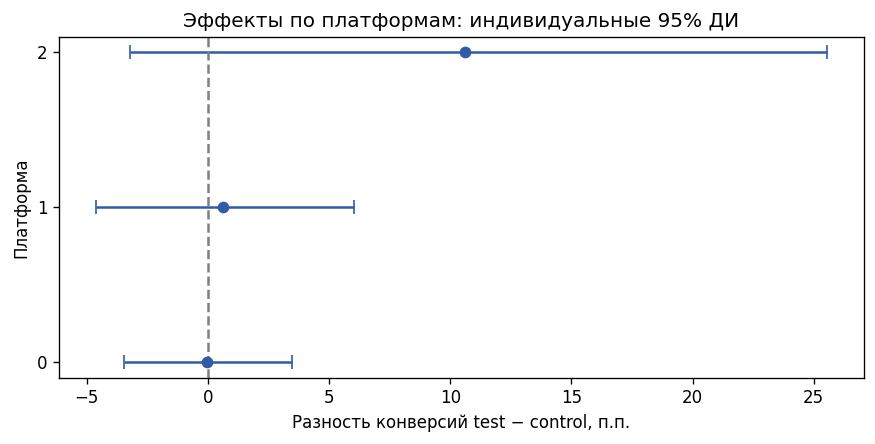

In [6]:
segments = pd.DataFrame([dict(platform=int(platform), **compare_proportions(part, 'converted'))
    for platform, part in df.groupby('platform')]).set_index('platform')
segments['p_bonferroni'] = multipletests(segments.fisher_p, alpha=ALPHA, method='bonferroni')[1]
segments['p_z_bonferroni'] = multipletests(segments.p, alpha=ALPHA, method='bonferroni')[1]
segments['significant'] = segments.p_bonferroni < ALPHA
print(segments)
fig, ax = plt.subplots(figsize=(7.4, 3.8))
ax.errorbar(100*segments.difference, segments.index,
    xerr=100*np.vstack([segments.difference-segments.ci_low, segments.ci_high-segments.difference]),
    fmt='o', capsize=4, color='#315ba6')
ax.axvline(0, color='gray', linestyle='--')
ax.set(yticks=[0, 1, 2], ylabel='Платформа', xlabel='Разность конверсий test − control, п.п.',
    title='Эффекты по платформам: индивидуальные 95% ДИ')
fig.tight_layout()
if 'get_ipython' in globals(): plt.show()
else: plt.close(fig)

## 6. Проверим время входа в эксперимент

Посмотрим, не приходят ли пользователи test систематически позже control.
Для этого сравним среднее время входа t-тестом Уэлча и распределения целиком
тестом Колмогорова — Смирнова. Построим гистограммы и накопленные распределения.

По одному итоговому CSV нельзя достоверно установить peeking — остановку
эксперимента после просмотра промежуточных результатов. Различия во времени
могут быть поводом разобраться, но не доказательством подглядывания. Для этого
нужны журнал проверок, правило остановки и промежуточные выборки. Если значимых
различий не найдём, это также не докажет, что peeking точно отсутствовал.

Разность средних: -0.011191 суток = -0.269 часа
Уэлч p=0.380933; KS D=0.037402, p=0.447196


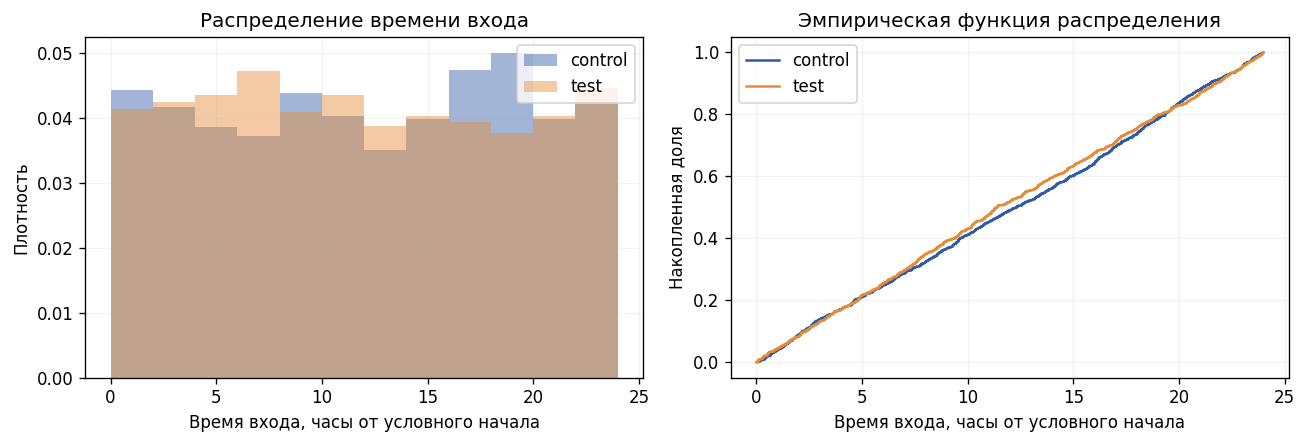


Назначение по интервалам времени:
 variant        control  test  test_share
entry_time                              
(-0.001, 0.2]      234   190    0.448113
(0.2, 0.4]         220   204    0.481132
(0.4, 0.6]         209   187    0.472222
(0.6, 0.8]         243   184    0.430913
(0.8, 1.0]         235   189    0.445755


In [7]:
ks = stats.ks_2samp(test.entry_time, control.entry_time)
time_difference = test.entry_time.mean() - control.entry_time.mean()
print(f'Разность средних: {time_difference:.6f} суток = {time_difference*24:.3f} часа')
print(f'Уэлч p={balance.loc["entry_time", "p"]:.6g}; KS D={ks.statistic:.6f}, p={ks.pvalue:.6g}')
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name, part, color in [('control', control, '#315ba6'), ('test', test, '#e78b35')]:
    hours = part.entry_time * 24
    axes[0].hist(hours, bins=np.linspace(0, 24, 13), density=True, alpha=.45, label=name, color=color)
    ordered = np.sort(hours)
    axes[1].step(ordered, np.arange(1, len(ordered)+1)/len(ordered), where='post', label=name, color=color)
axes[0].set(xlabel='Время входа, часы от условного начала', ylabel='Плотность', title='Распределение времени входа')
axes[1].set(xlabel='Время входа, часы от условного начала', ylabel='Накопленная доля', title='Эмпирическая функция распределения')
for ax in axes: ax.legend(); ax.grid(alpha=.15)
fig.tight_layout()
if 'get_ipython' in globals(): plt.show()
else: plt.close(fig)
time_bins = pd.crosstab(pd.cut(df.entry_time, np.linspace(0, 1, 6), include_lowest=True), df.variant)
time_bins['test_share'] = time_bins['test'] / time_bins[['control', 'test']].sum(axis=1)
print('\nНазначение по интервалам времени:\n', time_bins)

## 7. Разберёмся с генератором из условия

Сопоставим результаты с кодом задания. Здесь есть несколько важных деталей.

1. Сначала группа зависит от времени входа, но затем `variant` полностью
   перезаписывается через `random.choice`. Последовательных проверок и остановки
   при p < 0,05 в коде нет. Поэтому комментарий про peeking не совпадает с реализацией.
2. Группа затем меняется в зависимости от `weekend`, а вероятность конверсии
   тоже зависит от `weekend`. Получается смешение влияния фичи и состава групп.
3. У пользователей test на платформе 2 исходная конверсия заменяется новым
   случайным исходом с вероятностью 0,2. Это искусственное изменение данных,
   которое нельзя исправить одной поправкой на множественные проверки.
4. Переменная `true_effect = 0` дальше не используется. После подмены исходов
   итоговый контраст групп не обязан быть нулевым даже после коррекции `weekend`.
5. Ошибки в группах специально генерируются с разными вероятностями.

Это особенности генератора из условия. Мы анализируем предоставленный CSV и
не утверждаем, что по самому файлу можно доказать каждый механизм его создания.

## 8. Попробуем скорректировать оценку

Используем стратификацию по `weekend`. Сравним test и control отдельно для
выходных и будней, а затем усредним разницы с одинаковыми весами для обеих групп.
Вес каждой страты возьмём как её долю во всей выборке: w_s = N_s / N.
Тогда скорректированная разница равна Σ w_s · (CR_test,s − CR_control,s).

Дополнительно повторим расчёт для сочетаний `weekend × platform`. Так сравним
группы при одинаковом составе сразу по двум признакам. Платформу 2 исключать
не будем: это изменило бы исследуемую популяцию и могло бы скрыть проблему.

95% ДИ построим через дисперсию Σ w_s² · (s²_test,s / n_test,s + s²_control,s / n_control,s),
где s² — несмещённая выборочная дисперсия. Веса считаем фиксированными. Проверим,
что в каждой страте есть пользователи обоих вариантов. При малом числе событий
нормальное приближение может быть неточным, поэтому дополнительно построим
bootstrap-интервал: 5 000 повторов внутри каждой ячейки с теми же весами.

Такая коррекция полезна, если `weekend` и платформа измерены до воздействия и
учитывают причины различий между группами. Ненаблюдаемые причины она не убирает.
Она также не исправляет ошибки загрузки и искусственную замену исходов.

Страты weekend:
   stratum   weight  n_control  n_test  control_rate  test_rate  difference  variance
0       0 0.705012       1051     426      0.120837   0.100939   -0.019898  0.000315
1       1 0.294988         90     528      0.111111   0.147727    0.036616  0.001349

Страты weekend × platform:
                       stratum   weight  n_control  n_test  control_rate  test_rate  difference  variance
0  (np.int64(0), np.int64(0)) 0.461098        688     278      0.125000   0.082734   -0.042266  0.000433
1  (np.int64(0), np.int64(1)) 0.206205        306     126      0.114379   0.126984    0.012605  0.001219
2  (np.int64(0), np.int64(2)) 0.037709         57      22      0.105263   0.181818    0.076555  0.008766
3  (np.int64(1), np.int64(0)) 0.197136         63     350      0.063492   0.148571    0.085079  0.001322
4  (np.int64(1), np.int64(1)) 0.083532         21     154      0.238095   0.129870   -0.108225  0.009809
5  (np.int64(1), np.int64(2)) 0.014320          6      24      0.1666

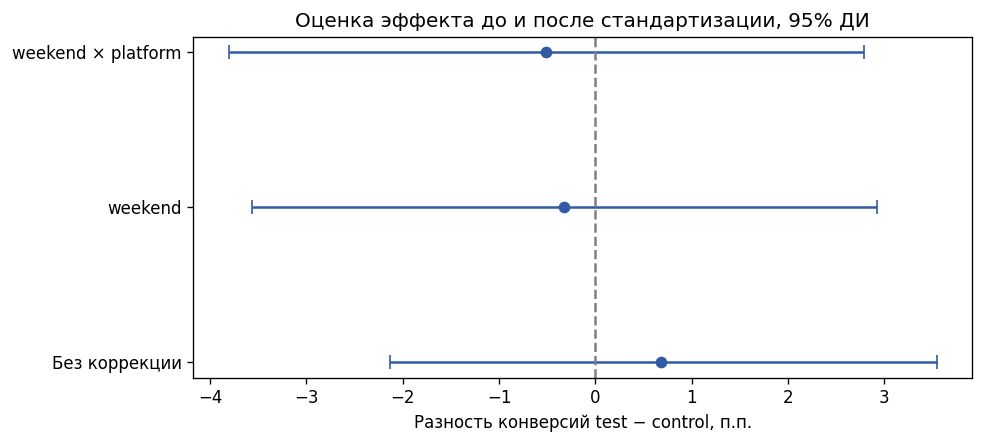

In [8]:
def standardize(data, covariates):
    rows = []
    boot = np.zeros(5000)
    rng = np.random.default_rng(20261115)
    for key, part in data.groupby(covariates[0] if len(covariates) == 1 else covariates):
        c = part.loc[part.variant == 'control', 'converted']
        t = part.loc[part.variant == 'test', 'converted']
        assert len(c) > 1 and len(t) > 1, 'Недостаточный overlap'
        w = len(part) / len(data)
        diff = t.mean() - c.mean()
        variance = t.var(ddof=1)/len(t) + c.var(ddof=1)/len(c)
        rows.append(dict(stratum=str(key), weight=w, n_control=len(c), n_test=len(t),
            control_rate=c.mean(), test_rate=t.mean(), difference=diff, variance=variance))
        # Для бинарного исхода это эквивалент ресемплинга пользователей внутри ячеек.
        boot += w*(rng.binomial(len(t), t.mean(), 5000)/len(t) - rng.binomial(len(c), c.mean(), 5000)/len(c))
    table = pd.DataFrame(rows)
    assert np.isclose(table.weight.sum(), 1)
    estimate = (table.weight * table.difference).sum()
    se = np.sqrt((table.weight**2 * table.variance).sum())
    ci = estimate + np.array([-1, 1])*stats.norm.ppf(.975)*se
    result = dict(difference=estimate, se=se, ci_low=ci[0], ci_high=ci[1],
        p=2*stats.norm.sf(abs(estimate/se)), bootstrap_low=np.quantile(boot, .025),
        bootstrap_high=np.quantile(boot, .975))
    return result, table

adj_weekend, strata_weekend = standardize(df, ['weekend'])
adj_full, strata_full = standardize(df, ['weekend', 'platform'])
print('Страты weekend:\n', strata_weekend)
print('\nСтраты weekend × platform:\n', strata_full)
adjustments = pd.DataFrame([dict(method='Без коррекции', **{k: primary[k] for k in ['difference','ci_low','ci_high','p']}),
    dict(method='weekend', **adj_weekend), dict(method='weekend × platform', **adj_full)]).set_index('method')
print('\nСравнение оценок:\n', adjustments)
fig, ax = plt.subplots(figsize=(8.3, 3.8))
ax.errorbar(100*adjustments.difference, np.arange(3),
    xerr=100*np.vstack([adjustments.difference-adjustments.ci_low, adjustments.ci_high-adjustments.difference]),
    fmt='o', capsize=4, color='#315ba6')
ax.axvline(0, color='gray', linestyle='--')
ax.set(yticks=np.arange(3), yticklabels=adjustments.index,
    xlabel='Разность конверсий test − control, п.п.', title='Оценка эффекта до и после стандартизации, 95% ДИ')
fig.tight_layout()
if 'get_ipython' in globals(): plt.show()
else: plt.close(fig)

## 9. Вывод


In [13]:
def pp(x):
    return f'{100*x:.3f}'

significant_platforms = segments.index[segments.significant].tolist()
time_p = balance.loc['entry_time', 'p']
time_verdict = ('Среднее время статистически различается.' if time_p < ALPHA else
    'Значимого различия среднего времени не обнаружено.')
raw_verdict = 'разница номинально значима' if primary['p'] < ALPHA else 'значимой разницы не нашли'
adj_verdict = 'разница после коррекции значима' if adj_weekend['p'] < ALPHA else 'значимой разницы после коррекции не нашли'
segment_table = '| Платформа | CR control, % | CR test, % | Разница, п.п. | Fisher p | Bonferroni p |\n|---|---:|---:|---:|---:|---:|\n'
segment_table += '\n'.join(f'| {platform} | {pp(row.control_rate)} | {pp(row.test_rate)} | {pp(row.difference)} | {row.fisher_p:.6g} | {row.p_bonferroni:.6g} |'
    for platform, row in segments.iterrows())
report = f'''# Домашнее задание №2. Разбор эксперимента

Для анализа использовали предоставленный файл `exp_data_seed_{SEED}.csv`.
В нём {len(df)} пользователей: {len(control)} в control и {len(test)} в test.
Данные заново не генерировали. Пропусков, повторов пользователей и недопустимых
значений не нашли, поэтому можем перейти к сравнению групп.

## Проверим, как распределились пользователи

По условию ожидаем 50/50. Получили χ² = {srm.statistic:.3f} и p-value = {srm.pvalue:.6g}.
{'Это меньше 0,05, поэтому SRM обнаружен: распределение групп не соответствует ожидаемому.' if srm.pvalue < ALPHA else 'Это больше 0,05: значимого отклонения от 50/50 не нашли.'}

Теперь посмотрим на weekend. В control доля таких пользователей равна
{pp(control.weekend.mean())}%, в test — {pp(test.weekend.mean())}%.
Разница составила {pp(balance.loc['weekend','difference'])} п.п.,
SMD = {balance.loc['weekend','smd']:.3f}, p-value Уэлча = {balance.loc['weekend','p']:.6g}.
{'Баланс weekend нарушен.' if balance.loc['weekend','p'] < ALPHA else 'Значимого различия weekend не обнаружили.'}
В генераторе из условия weekend влияет на конверсию, поэтому различие состава
групп может смещать оценку фичи. Проверка платформ дала p-value = {platform_balance.pvalue:.6g}.
{'Распределение платформ также значимо различается.' if platform_balance.pvalue < ALPHA else 'Значимого различия распределения платформ не нашли.'}

## Посмотрим на конверсию

В control получили {primary['x_control']} конверсий из {len(control)} —
{pp(primary['control_rate'])}%. В test — {primary['x_test']} из {len(test)},
или {pp(primary['test_rate'])}%.

Разница test − control равна **{pp(primary['difference'])} п.п.**,
относительный lift — **{pp(primary['lift'])}%**.
95% ДИ разницы: [{pp(primary['ci_low'])}; {pp(primary['ci_high'])}] п.п.
95% ДИ относительного lift: [{pp(lift_ci[0])}; {pp(lift_ci[1])}]%.
Z-тест дал p-value = {primary['p']:.6g}: {raw_verdict}.
Для сравнения, точный тест Фишера дал p-value = {primary['fisher_p']:.6g}.
Метод нельзя выбирать по тому, где результат удобнее. Эти расчёты пока не
позволяют сделать причинный вывод: сначала нужно учесть качество эксперимента.

## Проверим защитную метрику

В control ошибки были у {guardrail['x_control']} из {len(control)} пользователей
({pp(guardrail['control_rate'])}%), в test — у {guardrail['x_test']} из {len(test)}
({pp(guardrail['test_rate'])}%). Разница составила **{pp(guardrail['difference'])} п.п.**,
относительное изменение — {pp(guardrail['lift'])}%.
95% ДИ разницы: [{pp(guardrail['ci_low'])}; {pp(guardrail['ci_high'])}] п.п.
Односторонний Z-тест: p-value = {guardrail['p']:.6g};
точный тест Фишера: p-value = {guardrail['fisher_p']:.6g}.
{'Ошибок в test значимо больше. По условию задания этого достаточно, чтобы заблокировать запуск фичи.' if guardrail['p'] < ALPHA else 'Значимый рост ошибок не подтвердился. Это не равнозначно доказанной безопасности фичи.'}

## Сравним платформы

После поправки Бонферрони к точным тестам Фишера значимые платформы:
**{significant_platforms if significant_platforms else 'нет'}**.
Подробные расчёты для всех трёх платформ приведены в таблице ниже.

{segment_table}

Размеры групп и результаты Z-тестов можно посмотреть в таблице расчётов выше.
Даже значимый эффект в отдельной платформе не будет достаточным основанием для
запуска: проблемы распределения пользователей и качества данных могут остаться.
Если сегмент выбирали после просмотра результатов, его стоит проверить новым тестом.

## Проверим время входа

Разница средних test − control составила {time_difference:.6f} суток,
или {time_difference*24:.3f} часа. В среднем test приходит
{'позже' if time_difference > 0 else 'раньше'} control.
Уэлч дал p-value = {time_p:.6g}. {time_verdict}
Тест Колмогорова — Смирнова дал p-value = {ks.pvalue:.6g}:
{'различие распределений обнаружено' if ks.pvalue < ALPHA else 'значимого различия распределений не нашли'}.

По этим результатам нельзя доказать или исключить peeking. В самом генераторе
назначение по времени перезаписано случайным выбором, а промежуточных проверок
и остановки по p-value нет. Для проверки реальной ранней остановки понадобились бы логи.

## Попробуем учесть различие состава групп

После стандартизации по weekend получаем **{pp(adj_weekend['difference'])} п.п.**
вместо исходных **{pp(primary['difference'])} п.п.**.
95% ДИ: [{pp(adj_weekend['ci_low'])}; {pp(adj_weekend['ci_high'])}] п.п.,
p-value = {adj_weekend['p']:.6g}. То есть {adj_verdict}.
Bootstrap-интервал: [{pp(adj_weekend['bootstrap_low'])}; {pp(adj_weekend['bootstrap_high'])}] п.п.

Если учесть сразу weekend и platform, получаем **{pp(adj_full['difference'])} п.п.**,
95% ДИ [{pp(adj_full['ci_low'])}; {pp(adj_full['ci_high'])}] п.п.,
p-value = {adj_full['p']:.6g}. Bootstrap-интервал:
[{pp(adj_full['bootstrap_low'])}; {pp(adj_full['bootstrap_high'])}] п.п.

В каждой страте есть обе группы. Однако при небольшом числе событий интервалы
приближённые. Коррекция показывает, как меняется оценка при одинаковом составе
групп, но не устраняет все нарушения. Для причинного вывода нужно, чтобы
ковариаты измерялись до воздействия и учитывали все причины смешения.
Незначимый результат сам по себе не доказывает отсутствие эффекта.

## Сделаем итоговый вывод

**Решение: не rollout. Повторим эксперимент с изменениями.**

Принимаем решение по совокупности проверок, а не только по конверсии:
SRM p = {srm.pvalue:.6g}, баланс weekend p = {balance.loc['weekend','p']:.6g},
guardrail p = {guardrail['p']:.6g}, эффект после коррекции weekend —
{pp(adj_weekend['difference'])} п.п. при p = {adj_weekend['p']:.6g}.
На этих данных запуск фичи не обоснован.

В генераторе из задания отдельно меняется converted для test на платформе 2.
Поправка Бонферрони не исправляет такую подмену. Переменная true_effect = 0
в расчётах генератора не используется, поэтому скорректированный контраст
не обязан стать строго нулевым. Это ещё одна причина не считать данный тест
надёжной оценкой эффекта фичи.

Перед повторным запуском внесём следующие изменения:

1. Исправим ошибки загрузки и проверим исправление на небольшом техническом пилоте.
2. Настроим стабильное назначение по user_id с распределением 50/50 до воздействия.
   Не будем менять вариант в зависимости от weekend. При необходимости заранее
   проведём стратифицированную рандомизацию по платформе и календарным периодам.
3. Проверим логи назначения и событий, проведём A/A-тест. Уберём искусственную
   подмену конверсий на платформе 2.
4. Заранее зададим MDE, размер выборки, длительность с полными недельными циклами,
   допустимый рост ошибок, сегментные гипотезы и правило остановки.
5. Для обычного теста дождёмся запланированного окончания. Если нужен ранний
   анализ, заранее выберем последовательный метод. Новые сегментные находки
   подтвердим отдельным экспериментом.
'''

from IPython.display import display, Markdown
display(Markdown(report))
assert all(0 <= row['p'] <= 1 for row in [primary, guardrail, adj_weekend, adj_full])
assert np.isclose(primary['difference'], test.converted.mean() - control.converted.mean())
assert all(segments.p_bonferroni >= segments.fisher_p)


# Домашнее задание №2. Разбор эксперимента

Для анализа использовали предоставленный файл `exp_data_seed_4762709.csv`.
В нём 2095 пользователей: 1141 в control и 954 в test.
Данные заново не генерировали. Пропусков, повторов пользователей и недопустимых
значений не нашли, поэтому можем перейти к сравнению групп.

## Проверим, как распределились пользователи

По условию ожидаем 50/50. Получили χ² = 16.692 и p-value = 4.39742e-05.
Это меньше 0,05, поэтому SRM обнаружен: распределение групп не соответствует ожидаемому.

Теперь посмотрим на weekend. В control доля таких пользователей равна
7.888%, в test — 55.346%.
Разница составила 47.458 п.п.,
SMD = 1.186, p-value Уэлча = 3.911e-125.
Баланс weekend нарушен.
В генераторе из условия weekend влияет на конверсию, поэтому различие состава
групп может смещать оценку фичи. Проверка платформ дала p-value = 0.750321.
Значимого различия распределения платформ не нашли.

## Посмотрим на конверсию

В control получили 137 конверсий из 1141 —
12.007%. В test — 121 из 954,
или 12.683%.

Разница test − control равна **0.676 п.п.**,
относительный lift — **5.634%**.
95% ДИ разницы: [-2.137; 3.543] п.п.
95% ДИ относительного lift: [-15.978; 32.804]%.
Z-тест дал p-value = 0.638921: значимой разницы не нашли.
Для сравнения, точный тест Фишера дал p-value = 0.640987.
Метод нельзя выбирать по тому, где результат удобнее. Эти расчёты пока не
позволяют сделать причинный вывод: сначала нужно учесть качество эксперимента.

## Проверим защитную метрику

В control ошибки были у 27 из 1141 пользователей
(2.366%), в test — у 68 из 954
(7.128%). Разница составила **4.762 п.п.**,
относительное изменение — 201.219%.
95% ДИ разницы: [2.955; 6.715] п.п.
Односторонний Z-тест: p-value = 9.11666e-08;
точный тест Фишера: p-value = 1.33788e-07.
Ошибок в test значимо больше. По условию задания этого достаточно, чтобы заблокировать запуск фичи.

## Сравним платформы

После поправки Бонферрони к точным тестам Фишера значимые платформы:
**нет**.
Подробные расчёты для всех трёх платформ приведены в таблице ниже.

| Платформа | CR control, % | CR test, % | Разница, п.п. | Fisher p | Bonferroni p |
|---|---:|---:|---:|---:|---:|
| 0 | 11.984 | 11.943 | -0.041 | 1 | 1 |
| 1 | 12.232 | 12.857 | 0.625 | 0.902182 | 1 |
| 2 | 11.111 | 21.739 | 10.628 | 0.181599 | 0.544796 |

Размеры групп и результаты Z-тестов можно посмотреть в таблице расчётов выше.
Даже значимый эффект в отдельной платформе не будет достаточным основанием для
запуска: проблемы распределения пользователей и качества данных могут остаться.
Если сегмент выбирали после просмотра результатов, его стоит проверить новым тестом.

## Проверим время входа

Разница средних test − control составила -0.011191 суток,
или -0.269 часа. В среднем test приходит
раньше control.
Уэлч дал p-value = 0.380933. Значимого различия среднего времени не обнаружено.
Тест Колмогорова — Смирнова дал p-value = 0.447196:
значимого различия распределений не нашли.

По этим результатам нельзя доказать или исключить peeking. В самом генераторе
назначение по времени перезаписано случайным выбором, а промежуточных проверок
и остановки по p-value нет. Для проверки реальной ранней остановки понадобились бы логи.

## Попробуем учесть различие состава групп

После стандартизации по weekend получаем **-0.323 п.п.**
вместо исходных **0.676 п.п.**.
95% ДИ: [-3.566; 2.920] п.п.,
p-value = 0.845359. То есть значимой разницы после коррекции не нашли.
Bootstrap-интервал: [-3.704; 2.944] п.п.

Если учесть сразу weekend и platform, получаем **-0.508 п.п.**,
95% ДИ [-3.808; 2.793] п.п.,
p-value = 0.763009. Bootstrap-интервал:
[-3.778; 2.687] п.п.

В каждой страте есть обе группы. Однако при небольшом числе событий интервалы
приближённые. Коррекция показывает, как меняется оценка при одинаковом составе
групп, но не устраняет все нарушения. Для причинного вывода нужно, чтобы
ковариаты измерялись до воздействия и учитывали все причины смешения.
Незначимый результат сам по себе не доказывает отсутствие эффекта.

## Сделаем итоговый вывод

**Решение: не rollout. Повторим эксперимент с изменениями.**

Принимаем решение по совокупности проверок, а не только по конверсии:
SRM p = 4.39742e-05, баланс weekend p = 3.911e-125,
guardrail p = 9.11666e-08, эффект после коррекции weekend —
-0.323 п.п. при p = 0.845359.
На этих данных запуск фичи не обоснован.

В генераторе из задания отдельно меняется converted для test на платформе 2.
Поправка Бонферрони не исправляет такую подмену. Переменная true_effect = 0
в расчётах генератора не используется, поэтому скорректированный контраст
не обязан стать строго нулевым. Это ещё одна причина не считать данный тест
надёжной оценкой эффекта фичи.

Перед повторным запуском внесём следующие изменения:

1. Исправим ошибки загрузки и проверим исправление на небольшом техническом пилоте.
2. Настроим стабильное назначение по user_id с распределением 50/50 до воздействия.
   Не будем менять вариант в зависимости от weekend. При необходимости заранее
   проведём стратифицированную рандомизацию по платформе и календарным периодам.
3. Проверим логи назначения и событий, проведём A/A-тест. Уберём искусственную
   подмену конверсий на платформе 2.
4. Заранее зададим MDE, размер выборки, длительность с полными недельными циклами,
   допустимый рост ошибок, сегментные гипотезы и правило остановки.
5. Для обычного теста дождёмся запланированного окончания. Если нужен ранний
   анализ, заранее выберем последовательный метод. Новые сегментные находки
   подтвердим отдельным экспериментом.
